In [5]:
pip install -U scikit-learn

  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
   ---------------------------------------- 0.0/8.7 MB ? eta -:--:--
   -------------------------------- ------- 7.1/8.7 MB 43.7 MB/s eta 0:00:01
   ---------------------------------------- 8.7/8.7 MB 38.7 MB/s  0:00:00
   ---------------------------------------- 0.0/38.6 MB ? eta -:--:--
   ---------------- ----------------------- 16.0/38.6 MB 77.5 MB/s eta 0:00:01
   --------------------------------- ------ 32.5/38.6 MB 76.4 MB/s eta 0:00:01
   ---------------------------------------- 38.6/38.6 MB 64.5 MB/s  0:00:00

   ------------- -------------------------- 1/3 [scipy]
   ------------- -------------------------- 1/3 [scipy]
   ------------- -------------------------- 1/3 [scipy]
   ------------- -------------------------- 1/3 [scipy]
   ------------- -------------------------- 1/3 [scipy]
   ------------- -------------------------- 1/3 [scipy]
   ------------- -------------------------- 1/3 [scipy]
   -----------

In [6]:
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

df = pd.read_csv("../data/processed/clinical_notes_preprocessed.csv")
df.head()

,patient_id,note_text,clean_text,tokens,processed_text
0,0,Patient is a 32-year-old Male with a history o...,patient is a year old male with a history o...,"['patient', 'year', 'old', 'male', 'history', ...",patient year old male history healthy presenti...
1,1,Patient is a 65-year-old Female with a history...,patient is a year old female with a history...,"['patient', 'year', 'old', 'female', 'history'...",patient year old female history hypertension p...
2,2,Patient is a 20-year-old Female with a history...,patient is a year old female with a history...,"['patient', 'year', 'old', 'female', 'history'...",patient year old female history diabetes prese...
3,3,Patient is a 39-year-old Female with a history...,patient is a year old female with a history...,"['patient', 'year', 'old', 'female', 'history'...",patient year old female history asthma present...
4,4,Patient is a 69-year-old Male with a history o...,patient is a year old male with a history o...,"['patient', 'year', 'old', 'male', 'history', ...",patient year old male history hypertension pre...


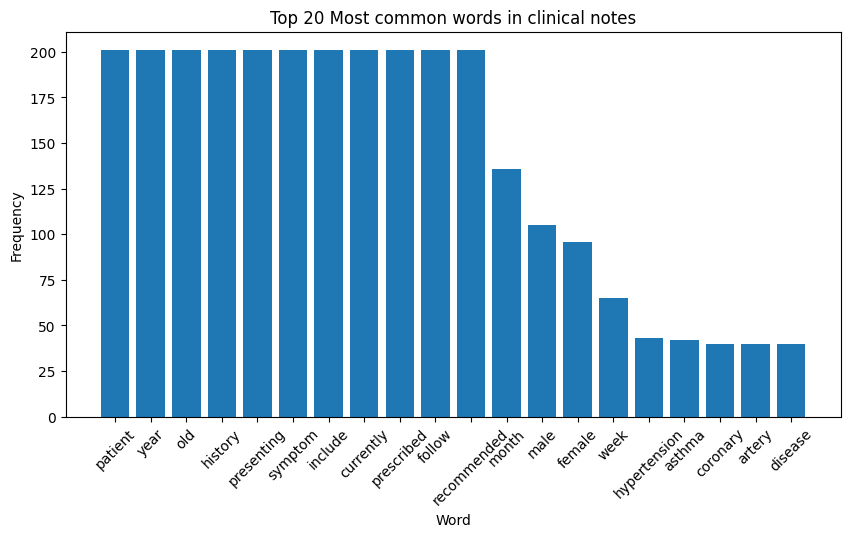

In [7]:
# combine all token in one list
all_words = " ".join(df["processed_text"]).split()

#count frequency of each word
word_counts = Counter(all_words)

#Take top 20
common_word = word_counts.most_common(20)

words, count = zip(*common_word)
plt.figure(figsize=(10,5))
plt.bar(words, count)
plt.xticks(rotation=45)
plt.title("Top 20 Most common words in clinical notes")
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.show()

In [8]:
vectorizer = CountVectorizer(max_features=20)
X_bow = vectorizer.fit_transform(df["processed_text"])

bow_df = pd.DataFrame(X_bow.toarray(),columns=vectorizer.get_feature_names_out())
bow_df.head()

,artery,asthma,coronary,currently,disease,female,follow,history,hypertension,include,male,month,old,patient,prescribed,presenting,recommended,symptom,week,year
0,0,0,0,1,0,0,1,1,0,1,1,0,1,1,1,1,1,1,1,1
1,0,0,0,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1
2,0,0,0,1,0,1,1,1,0,1,0,0,1,1,1,1,1,1,1,1
3,0,1,0,1,0,1,1,1,0,1,0,0,1,1,1,1,1,1,1,1
4,0,0,0,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1


In [9]:
tfidf = TfidfVectorizer(max_features=20)
X_tfidf = tfidf.fit_transform(df['processed_text'])

tfidf_df = pd.DataFrame(X_tfidf.toarray(),columns=tfidf.get_feature_names_out())
tfidf_df.head()

,artery,asthma,coronary,currently,disease,female,follow,history,hypertension,include,male,month,old,patient,prescribed,presenting,recommended,symptom,week,year
0,0.0,0.000000,0.0,0.234442,0.0,0.000000,0.234442,0.234442,0.000000,0.234442,0.385618,0.000000,0.234442,0.234442,0.234442,0.234442,0.234442,0.234442,0.496693,0.234442
1,0.0,0.000000,0.0,0.211745,0.0,0.367072,0.211745,0.211745,0.534461,0.211745,0.000000,0.293963,0.211745,0.211745,0.211745,0.211745,0.211745,0.211745,0.000000,0.211745
2,0.0,0.000000,0.0,0.232535,0.0,0.403112,0.232535,0.232535,0.000000,0.232535,0.000000,0.000000,0.232535,0.232535,0.232535,0.232535,0.232535,0.232535,0.492651,0.232535
3,0.0,0.509604,0.0,0.200075,0.0,0.346841,0.200075,0.200075,0.000000,0.200075,0.000000,0.000000,0.200075,0.200075,0.200075,0.200075,0.200075,0.200075,0.423881,0.200075
4,0.0,0.000000,0.0,0.213182,0.0,0.000000,0.213182,0.213182,0.538089,0.213182,0.350649,0.295958,0.213182,0.213182,0.213182,0.213182,0.213182,0.213182,0.000000,0.213182


In [10]:
print("Bag of Words Sample:")
print(bow_df.head(3))

print("\nTF-IDF Sample:")
print(tfidf_df.head(3))


Bag of Words Sample:
   artery  asthma  coronary  currently  disease  female  follow  history  \
0       0       0         0          1        0       0       1        1   
1       0       0         0          1        0       1       1        1   
2       0       0         0          1        0       1       1        1   

   hypertension  include  male  month  old  patient  prescribed  presenting  \
0             0        1     1      0    1        1           1           1   
1             1        1     0      1    1        1           1           1   
2             0        1     0      0    1        1           1           1   

   recommended  symptom  week  year  
0            1        1     1     1  
1            1        1     0     1  
2            1        1     1     1  

TF-IDF Sample:
   artery  asthma  coronary  currently  disease    female    follow   history  \
0     0.0     0.0       0.0   0.234442      0.0  0.000000  0.234442  0.234442   
1     0.0     0.0       0.0

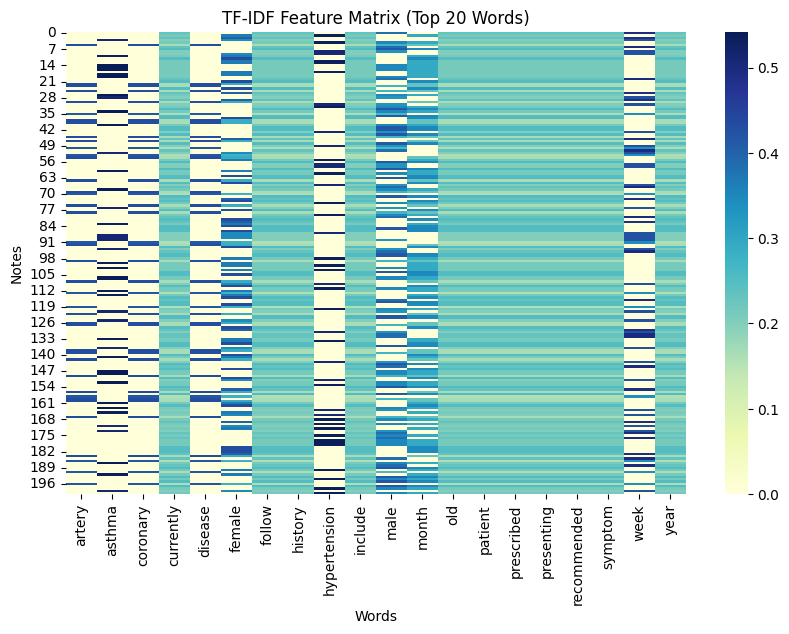

In [12]:
import seaborn as sns
plt.figure(figsize=(10, 6))
sns.heatmap(tfidf_df,   cmap="YlGnBu")
plt.title("TF-IDF Feature Matrix (Top 20 Words)")
plt.xlabel("Words")
plt.ylabel("Notes")
plt.show()